In [10]:
import pandas as pd
import matplotlib.pyplot as plt

In [11]:
df = pd.read_csv("../data/Clean_Dataset.csv")

In [12]:
df.head()

,Unnamed: 0,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price
0,0,SpiceJet,SG-8709,Delhi,Evening,zero,Night,Mumbai,Economy,2.17,1,5953
1,1,SpiceJet,SG-8157,Delhi,Early_Morning,zero,Morning,Mumbai,Economy,2.33,1,5953
2,2,AirAsia,I5-764,Delhi,Early_Morning,zero,Early_Morning,Mumbai,Economy,2.17,1,5956
3,3,Vistara,UK-995,Delhi,Morning,zero,Afternoon,Mumbai,Economy,2.25,1,5955
4,4,Vistara,UK-963,Delhi,Morning,zero,Morning,Mumbai,Economy,2.33,1,5955


In [13]:
df.shape

(300153, 12)

In [14]:
df.dtypes

Unnamed: 0            int64
airline                 str
flight                  str
source_city             str
departure_time          str
stops                   str
arrival_time            str
destination_city        str
class                   str
duration            float64
days_left             int64
price                 int64
dtype: object

In [15]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 300153 entries, 0 to 300152
Data columns (total 12 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        300153 non-null  int64  
 1   airline           300153 non-null  str    
 2   flight            300153 non-null  str    
 3   source_city       300153 non-null  str    
 4   departure_time    300153 non-null  str    
 5   stops             300153 non-null  str    
 6   arrival_time      300153 non-null  str    
 7   destination_city  300153 non-null  str    
 8   class             300153 non-null  str    
 9   duration          300153 non-null  float64
 10  days_left         300153 non-null  int64  
 11  price             300153 non-null  int64  
dtypes: float64(1), int64(3), str(8)
memory usage: 27.5 MB


In [16]:
df.isna().sum()

Unnamed: 0          0
airline             0
flight              0
source_city         0
departure_time      0
stops               0
arrival_time        0
destination_city    0
class               0
duration            0
days_left           0
price               0
dtype: int64

In [17]:
df.duplicated().sum()

np.int64(0)

In [18]:
df.describe()

,Unnamed: 0,duration,days_left,price
count,300153.000000,300153.000000,300153.000000,300153.000000
mean,150076.000000,12.221021,26.004751,20889.660523
std,86646.852011,7.191997,13.561004,22697.767366
min,0.000000,0.830000,1.000000,1105.000000
25%,75038.000000,6.830000,15.000000,4783.000000
50%,150076.000000,11.250000,26.000000,7425.000000
75%,225114.000000,16.170000,38.000000,42521.000000
max,300152.000000,49.830000,49.000000,123071.000000


| -----------------| --------------------  | -------------------- | 
| Variable         | Nature                | Type                 |
| airline          | Categorical           | Qualitative          |
| flight           | Categorical           | Qualitative          |
| source_city      | Categorical           | Qualitative          | 
| departure_time   | Categorical           | Qualitative          |
| stops            | Ordinale              | Qualitative ordinale |
| arrival_time     | Categorical           | Qualitative          |
| destination_city | Categorical           | Qualitative          |
| class            | Ordinale              | Qualitative ordinale |
| duration         | Quantitative continue | Numérique            |
| days_left        | Quantitative discrète | Numérique            |
| price            | Variable cible        | Quantitative         |


## Classification des variables selon leur nature

| Variable | Type de variable | Nature | Description |
|---|---|---|---|
| `airline` | Categorical | Qualitative | Compagnie aérienne |
| `flight` | Categorical | Qualitative | Numéro du vol |
| `source_city` | Categorical | Qualitative | Ville de départ |
| `departure_time` | Categorical | Qualitative | Période de départ |
| `stops` | Ordinale | Qualitative ordinale | Nombre d'escales avec un ordre |
| `arrival_time` | Categorical | Qualitative | Période d'arrivée |
| `destination_city` | Categorical | Qualitative | Ville d'arrivée |
| `class` | Ordinale | Qualitative ordinale | Classe du billet avec un ordre |
| `duration` | Quantitative continue | Quantitative | Durée du vol |
| `days_left` | Quantitative discrète | Quantitative | Nombre de jours avant le vol |
| `price` | Variable cible | Quantitative continue | Prix du billet à prédire |

### Variables quantitatives

- `duration` → **Continue**
- `days_left` → **Discrète**
- `price` → **Continue** et représente la **variable cible**

### Règle générale

- **Variable discrète** : valeurs séparées que l'on peut compter. Exemple : `days_left` = 1, 2, 3, 4...
- **Variable continue** : valeur que l'on peut mesurer et qui peut prendre des valeurs décimales. Exemple : `duration` = 2.5, 2.75, 12.22...

### Variable cible

`price` est la **variable cible (Target)** car c'est la variable que le modèle doit prédire.

### Remarque

`Unnamed: 0` est une colonne technique correspondant à un index importé depuis le fichier CSV. Elle ne représente pas une caractéristique utile du vol et sera supprimée lors du preprocessing.

In [19]:
df

,Unnamed: 0,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price
0,0,SpiceJet,SG-8709,Delhi,Evening,zero,Night,Mumbai,Economy,2.17,1,5953
1,1,SpiceJet,SG-8157,Delhi,Early_Morning,zero,Morning,Mumbai,Economy,2.33,1,5953
2,2,AirAsia,I5-764,Delhi,Early_Morning,zero,Early_Morning,Mumbai,Economy,2.17,1,5956
3,3,Vistara,UK-995,Delhi,Morning,zero,Afternoon,Mumbai,Economy,2.25,1,5955
4,4,Vistara,UK-963,Delhi,Morning,zero,Morning,Mumbai,Economy,2.33,1,5955
...,...,...,...,...,...,...,...,...,...,...,...,...
300148,300148,Vistara,UK-822,Chennai,Morning,one,Evening,Hyderabad,Business,10.08,49,69265
300149,300149,Vistara,UK-826,Chennai,Afternoon,one,Night,Hyderabad,Business,10.42,49,77105
300150,300150,Vistara,UK-832,Chennai,Early_Morning,one,Night,Hyderabad,Business,13.83,49,79099
300151,300151,Vistara,UK-828,Chennai,Early_Morning,one,Evening,Hyderabad,Business,10.00,49,81585


In [20]:
df["airline"].value_counts()

airline
Vistara      127859
Air_India     80892
Indigo        43120
GO_FIRST      23173
AirAsia       16098
SpiceJet       9011
Name: count, dtype: int64

<Axes: xlabel='airline'>

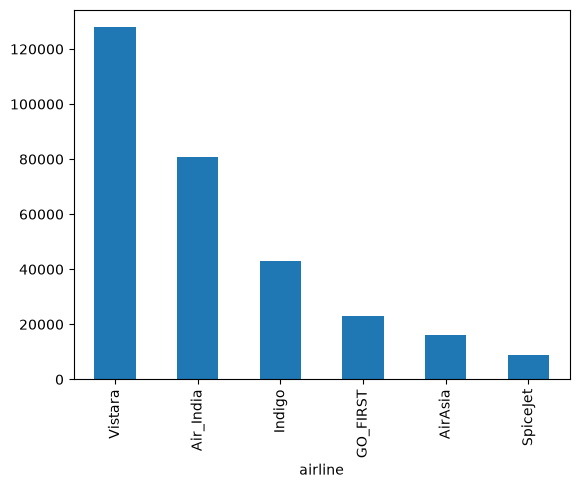

In [21]:
df["airline"].value_counts().plot(kind="bar")

In [22]:
df["flight"].value_counts().head(10)

flight
UK-706    3235
UK-772    2741
UK-720    2650
UK-836    2542
UK-822    2468
UK-828    2440
UK-874    2423
UK-832    2404
UK-826    2335
UK-860    2329
Name: count, dtype: int64

<Axes: xlabel='flight'>

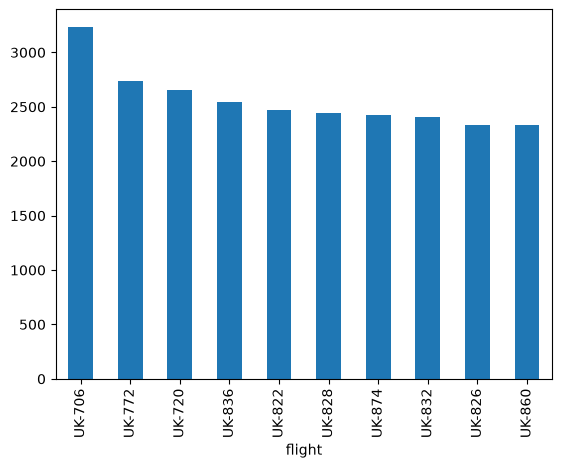

In [23]:
df["flight"].value_counts().head(10).plot(kind="bar")

In [24]:
df["source_city"].value_counts()


source_city
Delhi        61343
Mumbai       60896
Bangalore    52061
Kolkata      46347
Hyderabad    40806
Chennai      38700
Name: count, dtype: int64

<Axes: xlabel='source_city'>

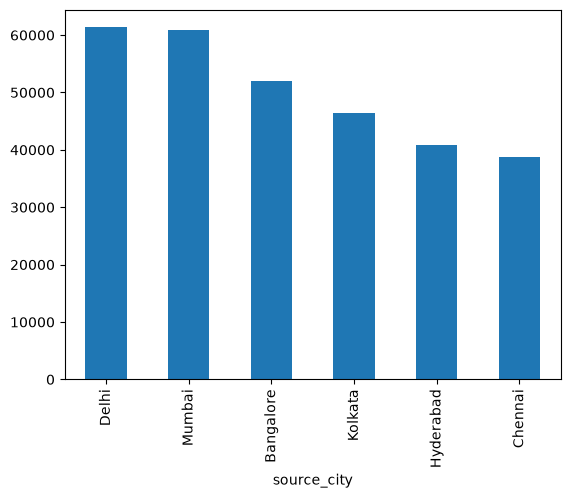

In [25]:
df["source_city"].value_counts().plot(kind="bar")

In [26]:
df["departure_time"].value_counts()

departure_time
Morning          71146
Early_Morning    66790
Evening          65102
Night            48015
Afternoon        47794
Late_Night        1306
Name: count, dtype: int64

In [27]:
df["stops"].value_counts()

stops
one            250863
zero            36004
two_or_more     13286
Name: count, dtype: int64

In [28]:
df["stops"].value_counts().

SyntaxError: invalid syntax (1077679222.py, line 1)

In [ ]:
df["arrival_time"].value_counts()

arrival_time
Night            91538
Evening          78323
Morning          62735
Afternoon        38139
Early_Morning    15417
Late_Night       14001
Name: count, dtype: int64

In [ ]:
df["destination_city"].value_counts()

destination_city
Mumbai       59097
Delhi        57360
Bangalore    51068
Kolkata      49534
Hyderabad    42726
Chennai      40368
Name: count, dtype: int64

In [ ]:
df["class"].value_counts()

class
Economy     206666
Business     93487
Name: count, dtype: int64

In [ ]:
df["duration"].describe()


count    300153.000000
mean         12.221021
std           7.191997
min           0.830000
25%           6.830000
50%          11.250000
75%          16.170000
max          49.830000
Name: duration, dtype: float64

<Axes: >

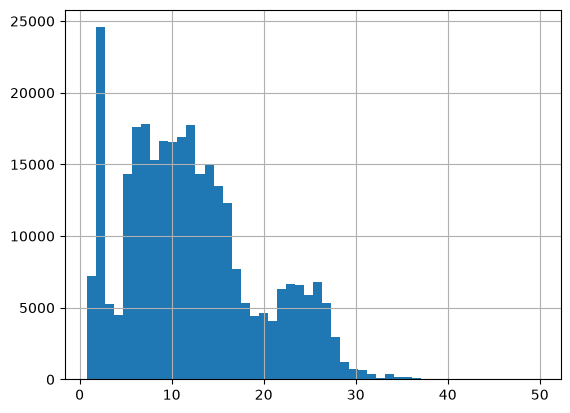

In [ ]:
df["duration"].hist(bins=50)

<Axes: >

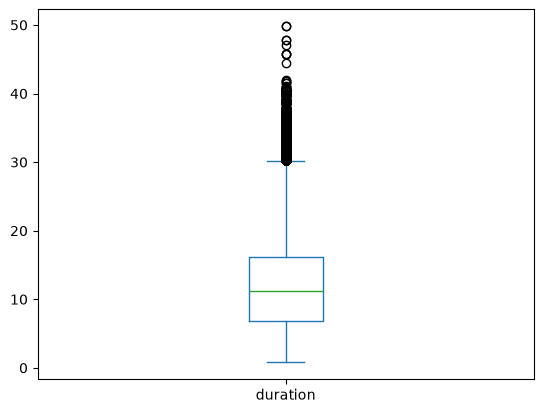

In [ ]:
df["duration"].plot(kind="box")

In [ ]:
df["days_left"].describe()

count    300153.000000
mean         26.004751
std          13.561004
min           1.000000
25%          15.000000
50%          26.000000
75%          38.000000
max          49.000000
Name: days_left, dtype: float64

<Axes: >

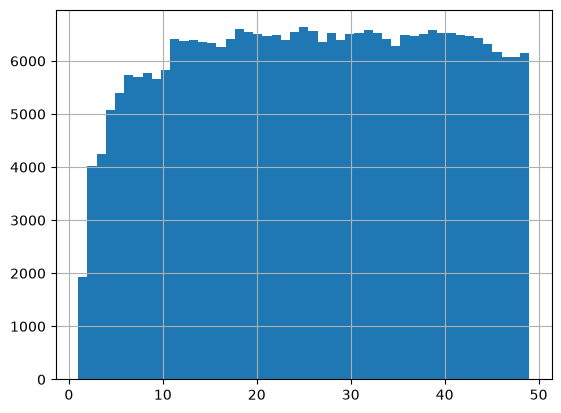

In [ ]:
df["days_left"].hist(bins=49)

<Axes: >

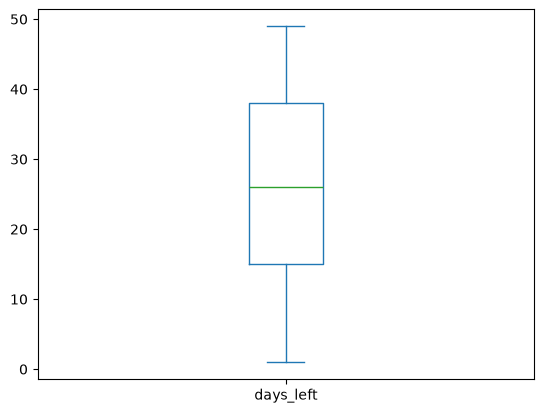

In [ ]:
df["days_left"].plot(kind="box")

In [ ]:
df["price"].describe()

count    300153.000000
mean      20889.660523
std       22697.767366
min        1105.000000
25%        4783.000000
50%        7425.000000
75%       42521.000000
max      123071.000000
Name: price, dtype: float64

<Axes: >

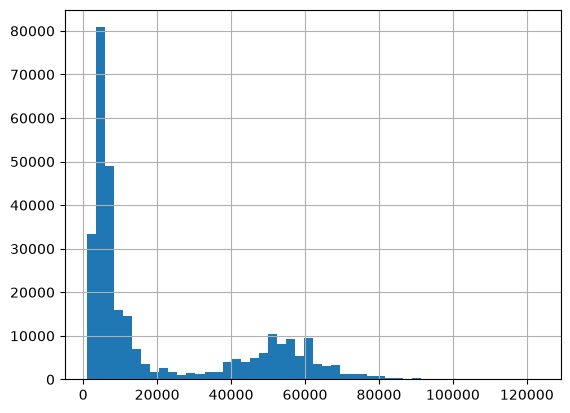

In [ ]:
df["price"].hist(bins=50)

<Axes: >

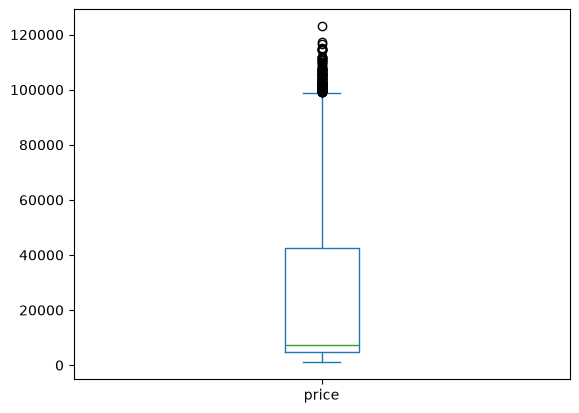

In [ ]:
df["price"].plot(kind="box")

In [ ]:
pd.crosstab(df["airline"] , df["class"])
# discret / descret

class,Business,Economy
airline,,
AirAsia,0,16098
Air_India,32898,47994
GO_FIRST,0,23173
Indigo,0,43120
SpiceJet,0,9011
Vistara,60589,67270


In [ ]:
# continue / continue


In [ ]:
df.groupby("class")["price"].mean()

class
Business    52540.081124
Economy      6572.342383
Name: price, dtype: float64

<Axes: title={'center': 'price'}, xlabel='class'>

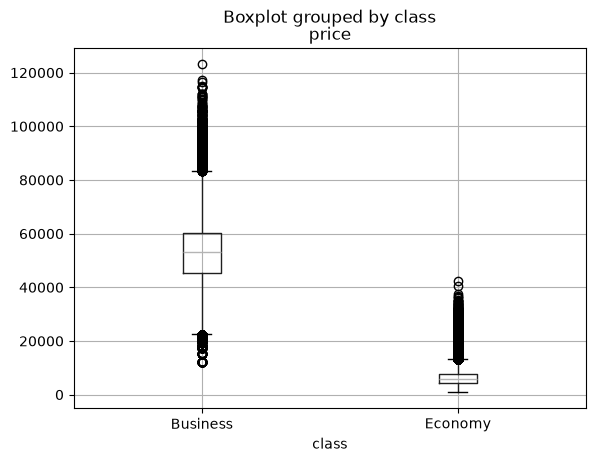

In [ ]:
df.boxplot(column="price", by="class")

<Axes: xlabel='class'>

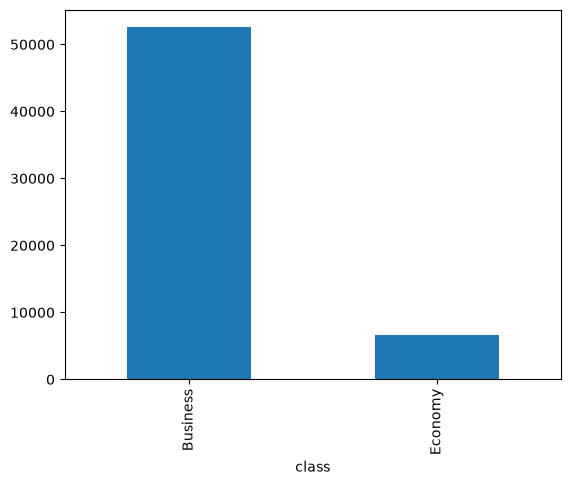

In [ ]:
df.groupby("class")["price"].mean().plot(kind="bar")

<Axes: xlabel='duration', ylabel='price'>

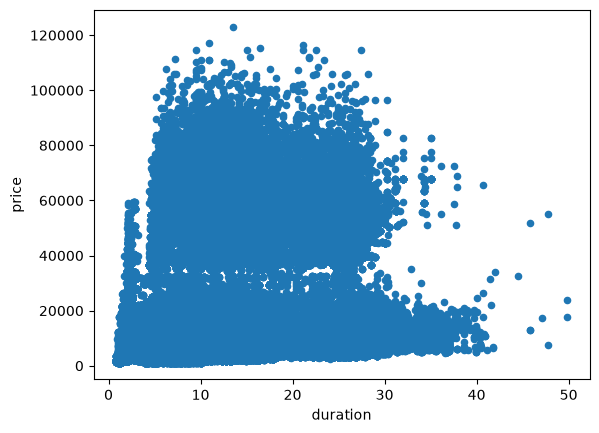

In [ ]:
df.plot.scatter(x="duration", y="price")

<!-- multivarie price ou class -->

<Axes: title={'center': 'price'}, xlabel='class'>

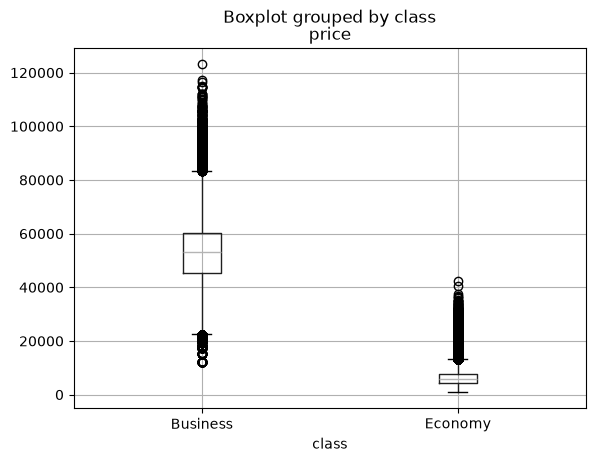

In [ ]:
df.boxplot(column="price", by="class")

<Axes: xlabel='class'>

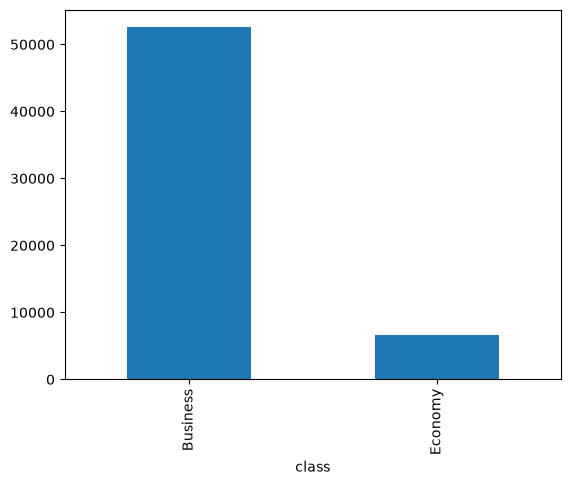

In [ ]:
df.groupby("class")["price"].mean().plot(kind="bar")


<!-- price ou aieline -->

<Axes: title={'center': 'price'}, xlabel='airline'>

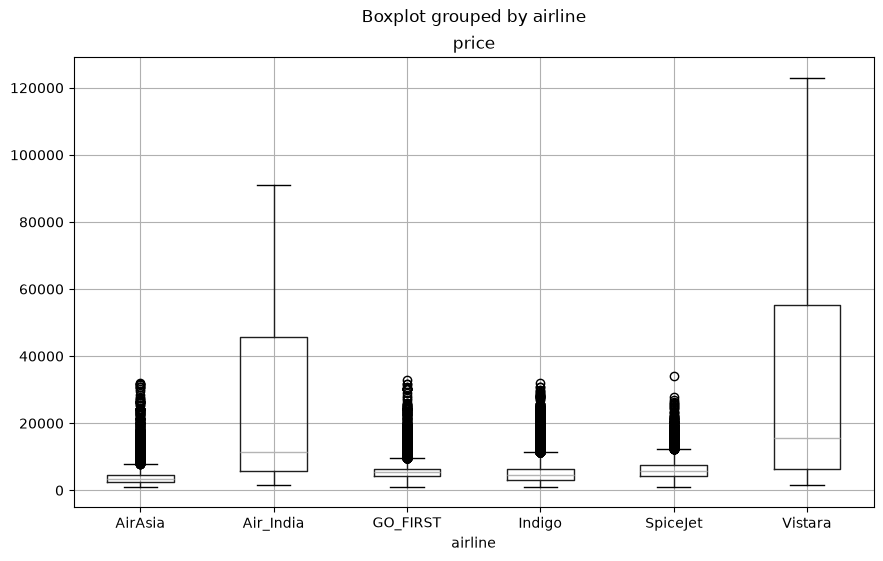

In [ ]:
df.boxplot(column="price", by="airline", figsize=(10,6))

<Axes: xlabel='airline'>

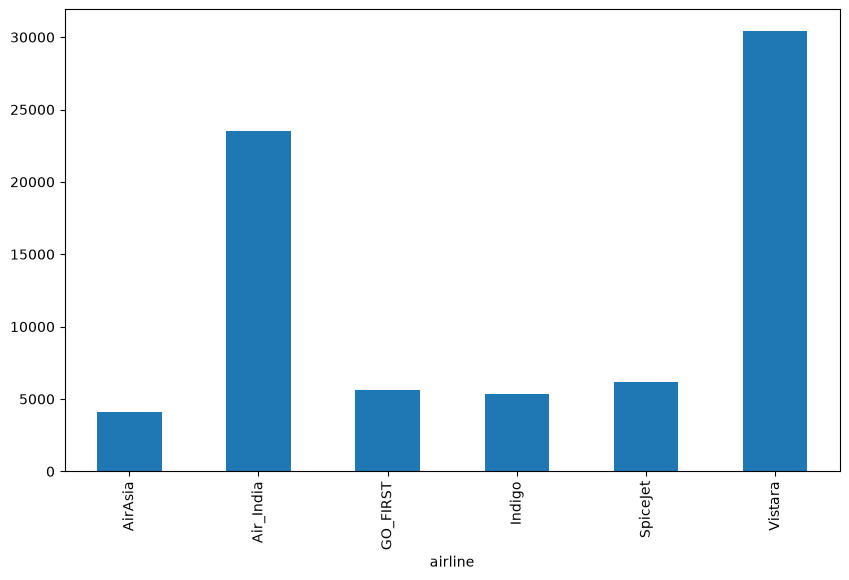

In [ ]:
df.groupby("airline")["price"].mean().plot(kind="bar", figsize=(10,6))

<!-- stops + price -->

<Axes: title={'center': 'price'}, xlabel='stops'>

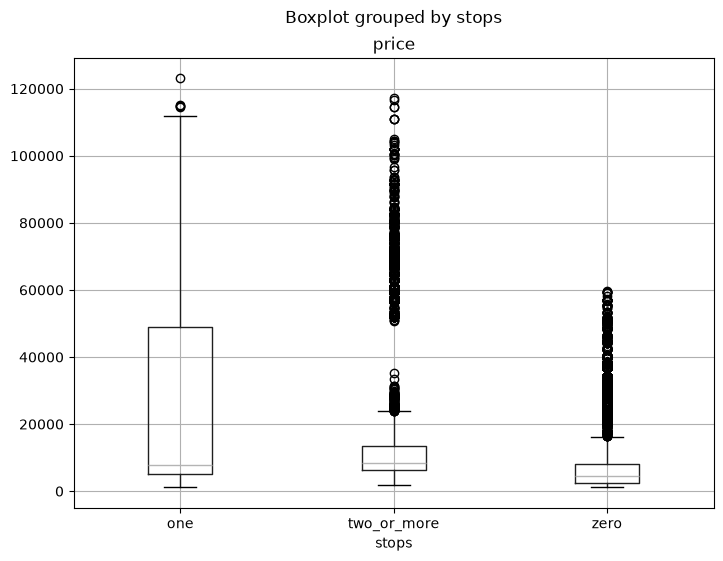

In [ ]:
df.boxplot(column="price", by="stops", figsize=(8,6))

<Axes: xlabel='stops'>

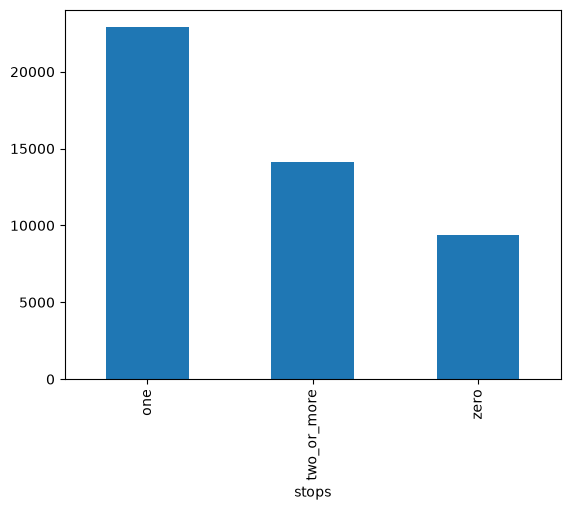

In [ ]:
df.groupby("stops")["price"].mean().plot(kind="bar")

<!-- departure_time + price -->

<Axes: title={'center': 'price'}, xlabel='departure_time'>

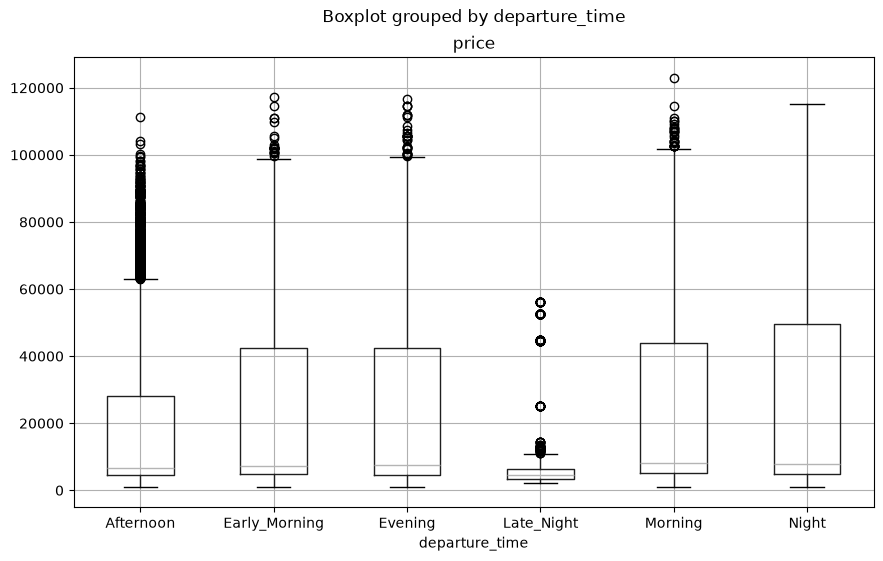

In [ ]:
df.boxplot(column="price", by="departure_time", figsize=(10,6))

<Axes: xlabel='departure_time'>

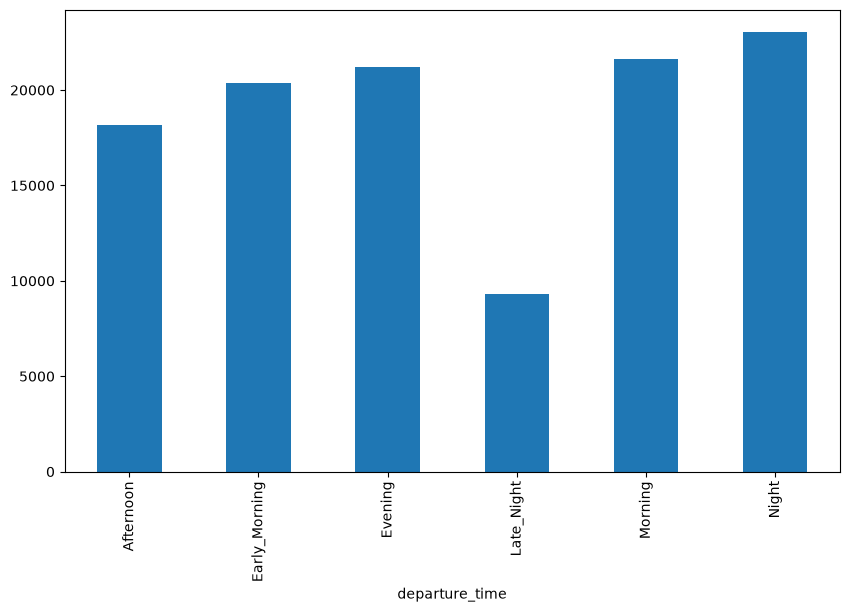

In [ ]:
df.groupby("departure_time")["price"].mean().plot(kind="bar", figsize=(10,6))

<!-- arrival_time + price -->

<Axes: title={'center': 'price'}, xlabel='arrival_time'>

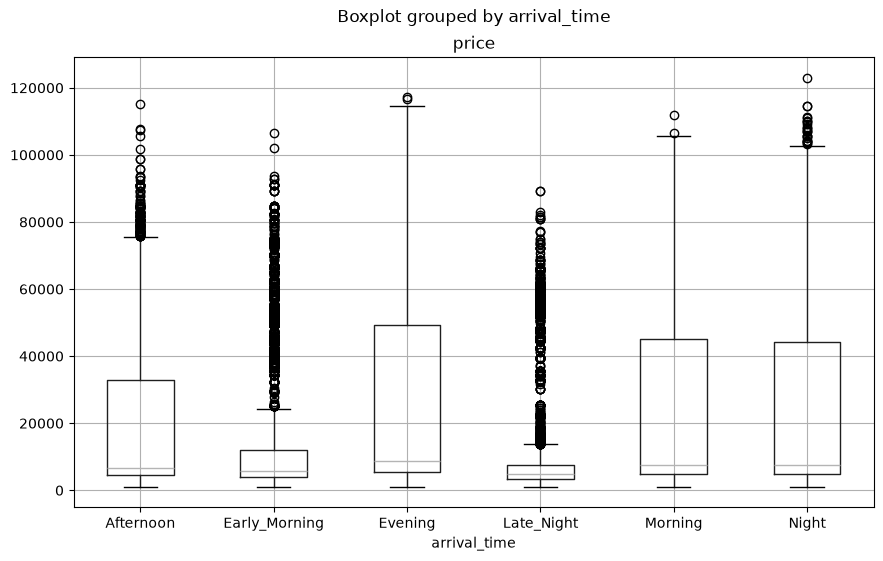

In [ ]:
df.boxplot(column="price", by="arrival_time", figsize=(10,6))

<Axes: xlabel='arrival_time'>

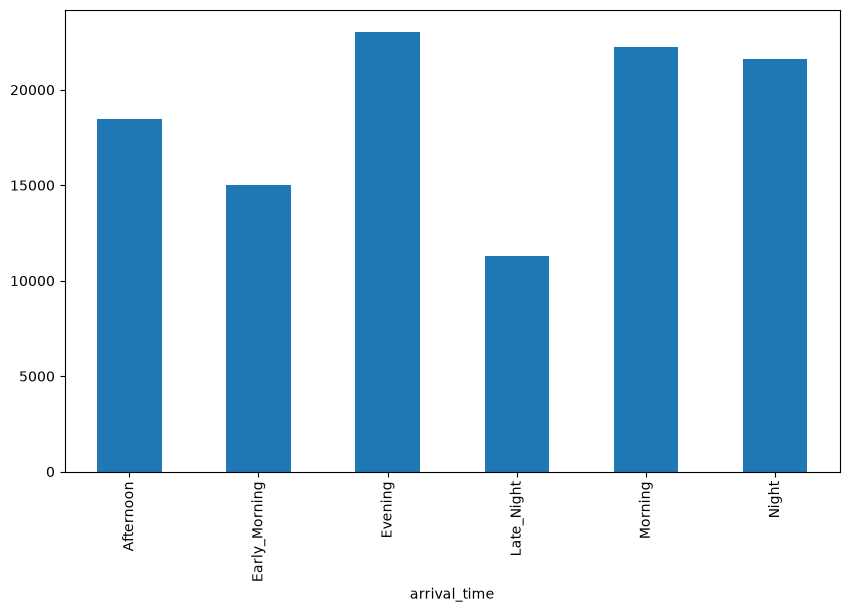

In [ ]:
df.groupby("arrival_time")["price"].mean().plot(kind="bar", figsize=(10,6))

<!-- duration + price -->

<Axes: xlabel='duration', ylabel='price'>

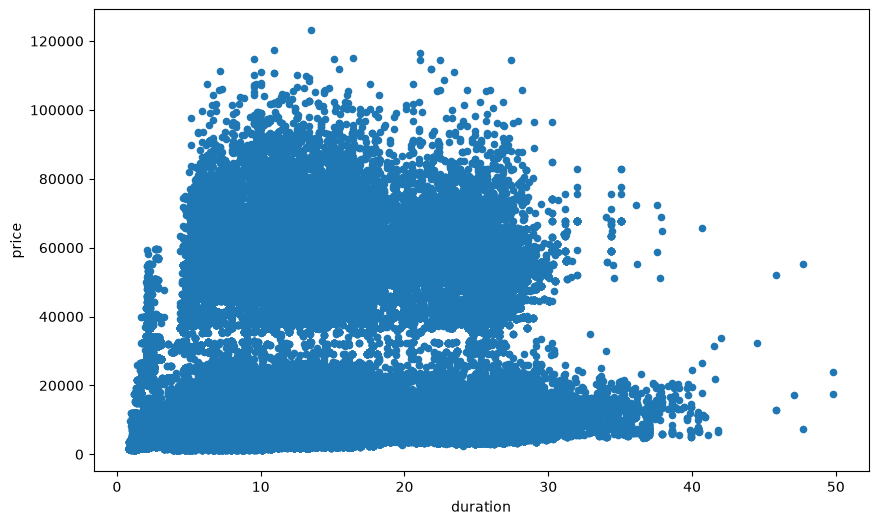

In [ ]:
df.plot.scatter(x="duration", y="price", figsize=(10,6))

<!-- days_left + price -->

<Axes: xlabel='days_left', ylabel='price'>

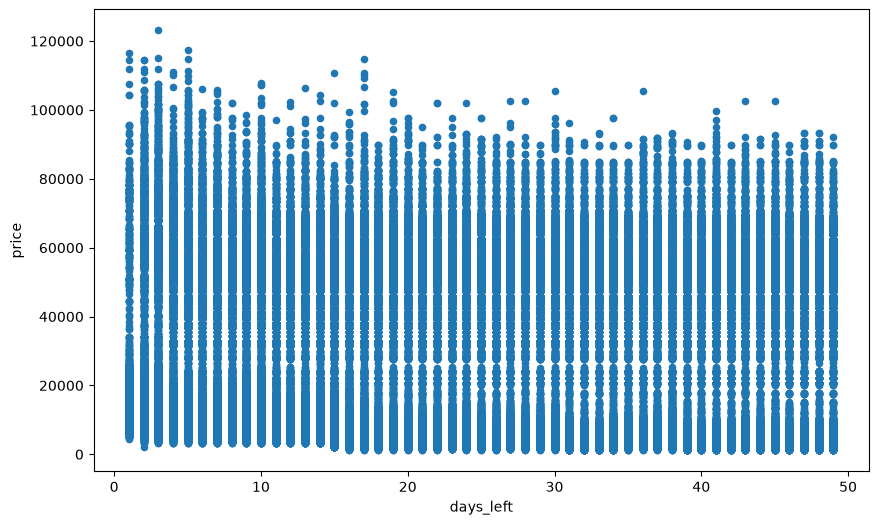

In [ ]:
df.plot.scatter(x="days_left", y="price", figsize=(10,6))

# preprocissing

In [ ]:
df.isna().sum()

Unnamed: 0          0
airline             0
flight              0
source_city         0
departure_time      0
stops               0
arrival_time        0
destination_city    0
class               0
duration            0
days_left           0
price               0
dtype: int64

<!-- Après vérification, aucune valeur manquante n'a été détectée dans le dataset. -->

In [30]:
X = df.drop(columns=["price", "Unnamed: 0"])

In [ ]:
X.columns

Index(['airline', 'flight', 'source_city', 'departure_time', 'stops',
       'arrival_time', 'destination_city', 'class', 'duration', 'days_left'],
      dtype='str')

In [31]:
y = df["price"]

In [ ]:
y.head()

0    5953
1    5953
2    5956
3    5955
4    5955
Name: price, dtype: int64

In [32]:
from sklearn.model_selection import train_test_split

In [33]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [ ]:
X_train.shape

(240122, 10)

In [ ]:
X_test.shape

(60031, 10)

In [ ]:
y_test.shape

(60031,)

In [ ]:
y_train.shape

(240122,)

In [34]:
from sklearn.preprocessing import OrdinalEncoder

In [35]:
ordinal_encoder = OrdinalEncoder(
    categories=[
        ["zero", "one", "two_or_more"],
        ["Economy", "Business"]
    ]
)

In [36]:
X_train_ordinal = ordinal_encoder.fit_transform(
    X_train[["stops", "class"]]
)

In [ ]:
X_train_ordinal[:5]

array([[1., 0.],
       [2., 0.],
       [1., 1.],
       [1., 0.],
       [1., 1.]])

In [ ]:
X_test_ordinal = ordinal_encoder.transform(
    X_test[["stops", "class"]]
)

In [ ]:
X_test_ordinal.shape

(60031, 2)

In [37]:
from sklearn.preprocessing import OneHotEncoder

In [38]:
onehot_encoder = OneHotEncoder(handle_unknown="ignore")

In [39]:
categorical_cols = [
    "airline",
    "flight",
    "source_city",
    "departure_time",
    "arrival_time",
    "destination_city"
]

In [ ]:
X_train_categorical = onehot_encoder.fit_transform(
    X_train[categorical_cols]
)

In [ ]:
X_test_categorical = onehot_encoder.transform(
    X_test[categorical_cols]
)

In [ ]:
X_train_categorical.shape

(240122, 1590)

In [40]:
from sklearn.preprocessing import StandardScaler

In [41]:
scaler = StandardScaler()

In [42]:
numerical_cols = ["duration", "days_left"]

In [ ]:
X_train_numerical = scaler.fit_transform(
    X_train[numerical_cols]
)

In [ ]:
X_train_numerical.shape

(240122, 2)

In [ ]:
X_test_numerical = scaler.transform(
    X_test[numerical_cols]
)

In [ ]:
pd.crosstab(df["airline"] , df["destination_city"])

destination_city,Bangalore,Chennai,Delhi,Hyderabad,Kolkata,Mumbai
airline,,,,,,
AirAsia,3437,1516,4433,1560,2789,2363
Air_India,11959,11141,14550,12022,13043,18177
GO_FIRST,4386,1488,5509,2576,3794,5420
Indigo,6772,6449,8133,6147,8437,7182
SpiceJet,1088,1172,2541,383,2054,1773
Vistara,23426,18602,22194,20038,19417,24182


In [43]:
from sklearn.compose import ColumnTransformer

In [44]:
ordinal_cols = ["stops", "class"]

In [45]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", scaler, numerical_cols),
        ("ord", ordinal_encoder, ordinal_cols),
        ("cat", onehot_encoder, categorical_cols)
    ]
)

In [ ]:
from sklearn.dummy import DummyRegressor

In [ ]:
dummy_model = DummyRegressor(strategy="mean")

In [ ]:
from sklearn.pipeline import Pipeline

In [ ]:
dummy_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", dummy_model)
])

In [ ]:
dummy_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['airline','flight','source_city',...,'class','duration','days_left']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('ord', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of colu

In [ ]:
y_pred_dummy = dummy_pipeline.predict(X_test)

In [ ]:
y_pred_dummy[:5]

array([20888.57241735, 20888.57241735, 20888.57241735, 20888.57241735,
       20888.57241735])

In [ ]:
from sklearn.metrics import mean_absolute_error

In [ ]:
mae_dummy = mean_absolute_error(y_test, y_pred_dummy)

In [ ]:
mae_dummy

19768.69424587037

In [ ]:
from sklearn.metrics import root_mean_squared_error

In [ ]:
rmse_dummy = root_mean_squared_error(y_test, y_pred_dummy)

In [ ]:
rmse_dummy

22704.23535747973

In [ ]:
from sklearn.metrics import r2_score

In [ ]:
r2_dummy = r2_score(y_test, y_pred_dummy)

In [ ]:
r2_dummy

-5.741993791552602e-08

In [ ]:
from sklearn.linear_model import LinearRegression

In [ ]:
linear_model = LinearRegression()

In [ ]:
linear_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", linear_model)
])

In [ ]:
linear_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['airline','flight','source_city',...,'class','duration','days_left']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('ord', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of colu

In [ ]:
y_pred_linear = linear_pipeline.predict(X_test)

In [ ]:
y_pred_linear[:5]

array([ 5980.34578359, 55913.04997681, 12170.10941486, 53357.04905918,
       10901.90733472])

In [ ]:
mae_linear = mean_absolute_error(y_test, y_pred_linear)
print(mae_linear)

4246.8482641873015


In [ ]:
rmse_linear = root_mean_squared_error(y_test, y_pred_linear)
print(rmse_linear)

6241.412473619274


In [ ]:
r2_linear = r2_score(y_test, y_pred_linear)
print(r2_linear)

0.9244295455668166


In [ ]:
from sklearn.linear_model import Ridge

In [ ]:
ridge_model = Ridge(alpha=1)

In [ ]:
ridge_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", ridge_model)
])

In [ ]:
ridge_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['airline','flight','source_city',...,'class','duration','days_left']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('ord', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of colu

In [ ]:
y_pred_ridge = ridge_pipeline.predict(X_test)
y_pred_ridge[:5]

array([ 5983.55437651, 55768.03549481, 12184.91901984, 53340.62586529,
       10910.03929071])

In [ ]:
mae_ridge = mean_absolute_error(y_test, y_pred_ridge)
print(mae_ridge)

4246.613959121012


In [ ]:
rmse_ridge = root_mean_squared_error(y_test, y_pred_ridge)
print(rmse_ridge)

6242.728438185282


In [ ]:
r2_ridge = r2_score(y_test, y_pred_ridge)
print(r2_ridge)

0.9243976750488194


In [ ]:
from sklearn.model_selection import GridSearchCV

In [ ]:
param_grid = {
    "model__alpha": [0.01, 0.1, 1, 10, 100]
}

In [ ]:
grid_search = GridSearchCV(
    ridge_pipeline,
    param_grid,
    cv=5,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)


In [ ]:
grid_search.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...ge(alpha=1))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__alpha': [0.01, 0.1, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_mean_absolute_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of information print

In [ ]:
grid_search.best_params_

{'model__alpha': 10}

In [ ]:
grid_search.best_score_

np.float64(-4267.086462131942)

In [ ]:
best_ridge = grid_search.best_estimator_

In [ ]:
y_pred_ridge_best = best_ridge.predict(X_test)

In [ ]:
mae_ridge_best = mean_absolute_error(y_test, y_pred_ridge_best)
print(mae_ridge_best
      )

4245.030310668805


In [ ]:
rmse_ridge_best = root_mean_squared_error(y_test, y_pred_ridge_best)
print(rmse_ridge_best)

6249.573859957245


In [ ]:
r2_ridge_best = r2_score(y_test, y_pred_ridge_best)
print(r2_ridge_best)

0.9242317817048222


In [ ]:
from sklearn.ensemble import RandomForestRegressor

In [ ]:
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

In [46]:
rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", rf_model)
])

In [ ]:
rf_pipeline.fit(X_train, y_train)